# **Lab Report: Wing-Twist Optimisation Assignment**
<h3 align="RIGHT">Submitted by: Kalyana Raama Bheema<h3>

# **Gradient Descent: Wing-Twist Optimization**

Gradient descent is a method to find the minimum of a function $J(\boldsymbol{\alpha})$.\
The gradient $\nabla J$ points in the direction where $J$ increases the most, so we take a small step in the opposite direction:\
$$\boldsymbol{\alpha}_{k+1} = \boldsymbol{\alpha}_k - \eta\, \nabla J(\boldsymbol{\alpha}_k)$$\
$\eta$ is the learning rate (step size). We repeat this until the gradient is almost zero, because at the minimum $\nabla J = 0$.\
If $\eta$ is too small it takes many steps. If $\eta$ is too large the steps overshoot and $J$ blows up.

**Prandtl's lifting-line theory:**\
The spanwise coordinate is $y = -\frac{b}{2}\cos\theta$, with $\theta \in [0, \pi]$, and the circulation is written as a sine series:
$$\Gamma(\theta) = 2bV_\infty \sum_n A_n \sin(n\theta)$$\
For a symmetric wing only odd terms $n = 1, 3, 5, \dots$ are non-zero. The coefficients $A_n$ come from the monoplane equation at $N$ points on half the wing:
$$\sum_{j=1}^{N} A_{n_j} \sin(n_j\theta_i)\left[\frac{4b}{a_0 c(\theta_i)} + \frac{n_j}{\sin\theta_i}\right] = \alpha_i, \quad n_j = 2j-1, \quad \theta_i = \frac{i\pi}{2N}$$\
This is a linear system $M\mathbf{A} = \boldsymbol{\alpha}$. Once $\mathbf{A}$ is known:
$$C_L = \pi AR\, A_1, \qquad C_{D_i} = \pi AR \sum_j n_j A_{n_j}^2, \qquad e = \frac{C_L^2}{\pi AR\, C_{D_i}}$$

## **Problem Statement:**

*   **Wing twist optimization**: Twisting the wing changes the local angle of attack $\alpha(y)$, and with it the induced drag. We want the twist that gives the smallest induced drag for a required lift coefficient.

*   **Wing data**: Rectangular wing, $AR = 8$, $b = 1$, $c = b/AR$, $a_0 = 2\pi$ per radian, target $C_L^* = 0.5$.

*   **Design variables**: The $N = 12$ local angles $\boldsymbol{\alpha} = (\alpha_1, \dots, \alpha_N)$.

*   **Optimization problem**: The lift must equal the target, so a quadratic penalty is added to the drag:
$$\min_{\boldsymbol{\alpha} \in \mathbb{R}^N} J(\boldsymbol{\alpha}) = C_{D_i}(\boldsymbol{\alpha}) + \mu\,(C_L(\boldsymbol{\alpha}) - C_L^*)^2, \quad \mu = 10$$

*   **Elliptic loading (exact answer)**:
$$\alpha(\theta) = \frac{C_L}{\pi AR}\left[1 + \frac{4b}{a_0 c}\sin\theta\right]$$
This makes $A_n = 0$ for all $n \ge 3$, which gives $e = 1$.

In [2]:
# do not change line below
from google.colab import files

# import required packages here
import numpy as np
import matplotlib.pyplot as plt

## **Task 1: Lifting-line function**

First a function that builds the matrix $M$:
$$M_{ij} = \sin(n_j\theta_i)\left[\frac{4b}{a_0 c} + \frac{n_j}{\sin\theta_i}\right]$$
Then a function that takes $\boldsymbol{\alpha}$, solves $M\mathbf{A} = \boldsymbol{\alpha}$ and returns $\mathbf{A}$, $C_L$, $C_{D_i}$ and $e$.

In [3]:
# wing data
AR = 8
b = 1
c = b / AR
a0 = 2 * np.pi
CL_target = 0.5

def matrix(N):
    theta = np.zeros(N)
    n = np.zeros(N)
    for i in range(N):
        theta[i] = (i + 1) * np.pi / (2 * N)
        n[i] = 2 * (i + 1) - 1
    M = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            M[i, j] = np.sin(n[j] * theta[i]) * (4 * b / (a0 * c) + n[j] / np.sin(theta[i]))
    return theta, n, M


def lifting_line(alpha):
    N = len(alpha)
    theta, n, M = matrix(N)
    A = np.linalg.solve(M, alpha)
    CL = np.pi * AR * A[0]
    CD = np.pi * AR * np.sum(n * A**2)
    e = CL**2 / (np.pi * AR * CD)
    return A, CL, CD, e

Now we do the validation for untwisted wing we just take the N values of $4, 8, 12, 16, 24$ and see where the slope converges and we know for untwisted wing all $\alpha_i$ are the same. If I put $\alpha_i = 1$ radian, then $C_L$ is directly the lift-curve slope $dC_L/d\alpha$.

In [4]:
Nl = [4, 8, 12, 16, 24]

print("  N   | dCL/dalpha (1/rad) |    e     |")
for N in Nl:
    alpha = np.ones(N)
    A, CL, CD, e = lifting_line(alpha)
    print(f"{N:<5} |      {CL:.6f}      | {e:.6f} |")

  N   | dCL/dalpha (1/rad) |    e     |
4     |      4.833329      | 0.939644 |
8     |      4.837454      | 0.936838 |
12    |      4.837656      | 0.936702 |
16    |      4.837689      | 0.936680 |
24    |      4.837701      | 0.936672 |


Here, from the table we can observe that the lift-curve slope goes to about 4.8377 per radian and $e$ goes to about 0.9367. From $N = 4$ to $N = 8$ the slope changes only in the 3rd decimal, and after $N = 12$ the change is in the 5th decimal. So the answer has converged and $N = 12$ is enough.\
The slope is less than $2\pi$ because the wing has finite span (the tip vortices reduce the angle the wing sees). $e < 1$ because its a rectangular wing.\
We can infer $N = 12$ from now on.

## **Task 2: Gradient descent from the untwisted wing**

**Gradient of $J$:**\
$\mathbf{A} = M^{-1}\boldsymbol{\alpha}$, so every $A_n$ is a linear function of $\boldsymbol{\alpha}$. Then
$$C_L = \pi AR\, A_1 \quad \Rightarrow \quad \frac{\partial C_L}{\partial \boldsymbol{\alpha}} = \pi AR \times (\text{first row of } M^{-1})$$
$$C_{D_i} = \pi AR \sum n_j A_{n_j}^2 \quad \Rightarrow \quad \frac{\partial C_{D_i}}{\partial \boldsymbol{\alpha}} = 2\pi AR\, (M^{-1})^T (n_j A_{n_j})$$
$$\nabla J = \frac{\partial C_{D_i}}{\partial \boldsymbol{\alpha}} + 2\mu\,(C_L - C_L^*)\frac{\partial C_L}{\partial \boldsymbol{\alpha}}$$

In [5]:
N = 12
theta, n, M = matrix(N)
Minv = np.linalg.inv(M) #doing the inverse of matrix M

def J(alpha, mu):
    A, CL, CD, e = lifting_line(alpha)
    return CD + mu * (CL - CL_target)**2


def grad_J(alpha, mu):
    A = Minv @ alpha
    CL = np.pi * AR * A[0]
    dCD = 2 * np.pi * AR * (Minv.T @ (n * A))
    dCL = np.pi * AR * Minv[0, :]
    return dCD + 2 * mu * (CL - CL_target) * dCL

Now, Let us define gradient descent function for our problem let us fix our tolerance as $10^-6$ and do the analysis for the untwisted wing that gives $C_L = C_L^*$:
$$\alpha_i = \frac{C_L^*}{dC_L/d\alpha} \quad \text{for all } i$$

In [6]:
def gradient_descent(grad, x0, lr, tol=1e-6):
    x = x0.copy()
    k = 0
    while True:
        g = grad(x)
        if np.linalg.norm(g) < tol:
            return x, k, "converged"
        if np.linalg.norm(g) > 1e6:
            return x, k, "diverged"
        x = x - lr * g
        k = k + 1
    return x, k

A, slope, CD, e = lifting_line(np.ones(N))
alpha0 = np.ones(N) * CL_target / slope

A0, CL0, CD0, e0 = lifting_line(alpha0)
print("untwisted angle =", np.degrees(alpha0[0]), "deg")
print("CL =", CL0, "  CDi =", CD0, "  e =", e0)

untwisted angle = 5.921853387014592 deg
CL = 0.49999999999999994   CDi = 0.010619370202042004   e = 0.9367018715790423


Running gradient descent with different fixed learning rates ($\mu = 10$):

In [7]:
mu = 10
lrl = [0.005, 0.01, 0.02, 0.03, 0.038, 0.039, 0.04, 0.05]

print("  lr    | iterations |      result      |      J       |")
for lr in lrl:
    alpha, k, status = gradient_descent(lambda a: grad_J(a, mu), alpha0, lr)
    print(f"{lr:<7} | {k:<10} | {status:<16} | {J(alpha, mu):.6e} |")

  lr    | iterations |      result      |      J       |
0.005   | 123656     | converged        | 9.907762e-03 |
0.01    | 61827      | converged        | 9.907762e-03 |
0.02    | 30912      | converged        | 9.907762e-03 |
0.03    | 20607      | converged        | 9.907762e-03 |
0.038   | 16268      | converged        | 9.907762e-03 |
0.039   | 16118      | converged        | 9.907762e-03 |
0.04    | 337        | diverged         | 9.911766e+09 |
0.05    | 38         | diverged         | 2.049274e+10 |


Here, first i checked with learning rates $ 0.005, 0.01, 0.02, 0.03, 0.04, 0.05 $ then i observed that max learning rate is in between 0.03 and 0.04. as the iterations are low around 0.04 so i tried 0.038, 0.039 there is the largest rate it converges.
**So the largest learning rate that still converges is about 0.039.**

## **Task 3: Optimized wing ($\mu = 10$)**

### **(a) $C_L$, $C_{D_i}$, $e$ and reduction in induced drag**

I use the largest learning rate that converges, $\eta = 0.039$, with a smaller tolerance to get a more accurate answer.

In [11]:
mu = 10
alpha_opt, k, status = gradient_descent(lambda a: grad_J(a, mu), alpha0, 0.039, tol=1e-8)
A_opt, CL_opt, CD_opt, e_opt = lifting_line(alpha_opt)
reduction = (CD0 - CD_opt) / CD0 * 100

print("           |    CL    |     CDi      |    e     |")
print(f"untwisted  | {CL0:.6f} | {CD0:.6e} | {e0:.6f} |")
print(f"optimized  | {CL_opt:.6f} | {CD_opt:.6e} | {e_opt:.6f} |")
print()
print("reduction in induced drag =", round(reduction, 2), "%")

           |    CL    |     CDi      |    e     |
untwisted  | 0.500000 | 1.061937e-02 | 0.936702 |
optimized  | 0.498018 | 9.868497e-03 | 1.000000 |

reduction in induced drag = 7.07 %


Here, we can observe that the optimized wing has $e = 1$, which is the best possible value, and the induced drag is reduced by about 7%.\
Because we used $C_L = C_L^*$, the optimized $C_L$ is about 0.4% below 0.5. At exactly $C_L = 0.5$ with $e = 1$ the drag would be $0.5^2/(8\pi) = 9.947 \times 10^{-3}$, which is a 6.3% reduction. So a small part of the 7.07% comes from the slightly lower lift.

### **(b) Optimized $\alpha_i$ vs analytical distribution (4)**

$y = -\frac{b}{2}\cos\theta$, so $\dfrac{2y}{b} = -\cos\theta$. For the analytical curve I use $C_L = C_L^*$.

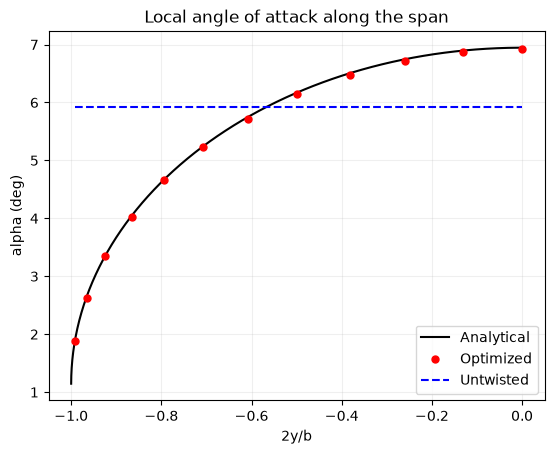

In [12]:
th = np.linspace(0.001, np.pi/2, 200)
alpha_exact = CL_target / (np.pi * AR) * (1 + 4 * b / (a0 * c) * np.sin(th))

plt.plot(-np.cos(th), np.degrees(alpha_exact), 'k', label='Analytical')
plt.plot(-np.cos(theta), np.degrees(alpha_opt), 'r.', markersize=10, label='Optimized')
plt.plot(-np.cos(theta), np.degrees(alpha0), 'b--', label='Untwisted')
plt.xlabel('2y/b')
plt.ylabel('alpha (deg)')
plt.title('Local angle of attack along the span')
plt.grid(True, alpha=0.2)
plt.legend(loc='lower right')
plt.show()

Here, the optimized angles lie on the analytical curve. The root ($2y/b = 0$) has the largest angle, about 6.9°, and the tip ($2y/b = -1$) has the smallest, about 1.9°. So the optimizer found the elliptic twist by itself.

### **(c) Spanwise lift distribution $\Gamma/\Gamma_{root}$**

$$\Gamma(\theta) \propto \sum A_n \sin(n\theta), \qquad \text{root is at } \theta = \pi/2$$
I plot the full span ($\theta$ from 0 to $\pi$, so $2y/b$ from $-1$ to $1$) and compare with the ellipse $\sqrt{1 - (2y/b)^2}$.

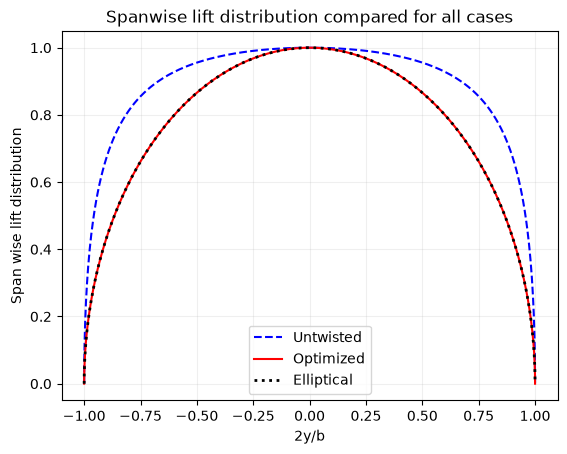

In [15]:
th = np.linspace(0, np.pi, 300)
y = -np.cos(th)

G0 = np.zeros_like(th)
G1 = np.zeros_like(th)
G0_root = 0
G1_root = 0
for j in range(N):
    G0 = G0 + A0[j] * np.sin(n[j] * th)
    G1 = G1 + A_opt[j] * np.sin(n[j] * th)
    G0_root = G0_root + A0[j] * np.sin(n[j] * np.pi/2)
    G1_root = G1_root + A_opt[j] * np.sin(n[j] * np.pi/2)

plt.plot(y, G0 / G0_root, 'b--', label='Untwisted')
plt.plot(y, G1 / G1_root, 'r', label='Optimized')
plt.plot(y, np.sqrt(1 - y**2), 'k:', linewidth=2, label='Elliptical')
plt.xlabel('2y/b')
plt.ylabel('Span wise lift distribution')
plt.title('Spanwise lift distribution compared for all cases')
plt.grid(True, alpha=0.2)
plt.legend(loc='lower center')
plt.show()

Here, the optimized lift distribution is right on top of the ellipse. The untwisted wing carries too much lift near the tips compared to the ellipse. More lift near the tips means stronger tip vortices and more downwash, and that is where the extra induced drag comes from.

## **Task 4: Effect of $\mu$**
The Hessian $H$ is the matrix of second derivatives of $J$, $H_{ij} = \dfrac{\partial^2 J}{\partial \alpha_i\, \partial \alpha_j}$. It tells how curved $J$ is in every direction. Its eigenvalues $\lambda$ are the curvatures along the main directions: big $\lambda$ = steep direction, small $\lambda$ = flat direction.

**Step 1: Write everything in terms of $\boldsymbol{\alpha}$**

From the lifting-line system:
$$\mathbf{A} = M^{-1}\boldsymbol{\alpha} \quad \text{--- (1)}$$
Let $\mathbf{m}$ be the first row of $M^{-1}$. Then from (1):
$$A_1 = m_1\alpha_1 + m_2\alpha_2 + \dots + m_N\alpha_N = \mathbf{m}\cdot\boldsymbol{\alpha} \quad \text{--- (2)}$$
So
$$C_L = \pi AR\, A_1 = \pi AR\,(\mathbf{m}\cdot\boldsymbol{\alpha}) \quad \text{--- (3)}, \qquad C_{D_i} = \pi AR \sum_j n_j A_j^2 \quad \text{--- (4)}$$

**Step 2: Drag part**

Differentiate (4) once, using (1):
$$\frac{\partial C_{D_i}}{\partial \boldsymbol{\alpha}} = 2\pi AR\,(M^{-1})^T (n_j A_j)$$
Differentiate again. $A_j$ is linear in $\boldsymbol{\alpha}$ from (1), so one more $M^{-1}$ comes in:
$$\frac{\partial^2 C_{D_i}}{\partial \boldsymbol{\alpha}^2} = 2\pi AR\,(M^{-1})^T\, \text{diag}(n)\, M^{-1} \quad \text{--- (5)}$$
$\text{diag}(n)$ is an $N \times N$ matrix with $1, 3, 5, \dots, 2N-1$ on the diagonal and zeros everywhere else.

**Step 3: Penalty part**

From (3), $\dfrac{\partial C_L}{\partial \boldsymbol{\alpha}} = \pi AR\,\mathbf{m}$. Differentiate the penalty once:
$$\frac{\partial}{\partial \boldsymbol{\alpha}}\left[\mu\,(C_L - C_L^*)^2\right] = 2\mu\,(C_L - C_L^*)\,\pi AR\,\mathbf{m}$$
Differentiate again. $C_L^*$ is a constant, so only $C_L$ gives another $\pi AR\,\mathbf{m}$:
$$\frac{\partial^2}{\partial \boldsymbol{\alpha}^2}\left[\mu\,(C_L - C_L^*)^2\right] = 2\mu\,(\pi AR)^2\,\mathbf{m}\,\mathbf{m}^T \quad \text{--- (6)}$$
$\mathbf{m}\,\mathbf{m}^T$ is an $N \times N$ matrix whose $(i, j)$ entry is $m_i \times m_j$.

**Step 4: Add (5) and (6)**
$$\mathbf{H = 2\pi AR\,(M^{-1})^T\, \text{diag}(n)\, M^{-1} + 2\mu\,(\pi AR)^2\,\mathbf{m}\,\mathbf{m}^T}$$
There is no $\boldsymbol{\alpha}$ in $H$, because $J$ is quadratic. So $H$ is the same everywhere and only changes with $\mu$. A bigger $\mu$ makes the second term bigger, which makes the $C_L$ direction steeper.

**Condition number:** $\kappa = \dfrac{\lambda_{max}}{\lambda_{min}}$, where $\lambda$ are the eigenvalues of $H$.

**Best fixed learning rate:** for a quadratic function the best fixed learning rate is
$$\eta = \frac{2}{\lambda_{max} + \lambda_{min}}$$
For $\mu = 10$ this gives 0.0390, the same as the largest learning rate found in Task 2. I use this for each $\mu$.

In [23]:
def hessian(mu):
    m = Minv[0, :]                                        # first row of M^-1
    H_drag = 2 * np.pi * AR * Minv.T @ np.diag(n) @ Minv  # equation (5)
    H_pen = 2 * mu * (np.pi * AR)**2 * np.outer(m, m)     # equation (6)
    return H_drag + H_pen

mul = [1, 10, 100]

print(" mu  |  |CL - CL*|  |  kappa   |    lr     | iterations |")
for mu in mul:
    lam = np.linalg.eigvalsh(hessian(mu))
    kappa = lam.max() / lam.min()
    lr = 2 / (lam.max() + lam.min())

    alpha, k, status = gradient_descent(lambda a: grad_J(a, mu), alpha0, lr, tol=1e-8)
    A, CL, CD, e = lifting_line(alpha)
    print(f"{mu:<4} |  {abs(CL - CL_target):.3e}   | {kappa:<8.1f} | {lr:.6f}  | {k:<10} |")

 mu  |  |CL - CL*|  |  kappa   |    lr     | iterations |
1    |  1.913e-02   | 515.6    | 0.375318  | 4030       |
10   |  1.982e-03   | 4969.9   | 0.039006  | 38847      |
100  |  1.989e-04   | 49513.4  | 0.003916  | 387004     |


Here, from the table we can observe that when $\mu$ becomes 10 times larger, $|C_L - C_L^*|$ becomes about 10 times smaller, so the lift gets closer to the target.\
But $\kappa$ also becomes about 10 times larger. Because of this the learning rate has to be smaller and the number of iterations becomes about 10 times larger.\
So there is a trade-off: a large $\mu$ gives a more accurate lift, but gradient descent becomes much slower.

## **References**

1.  [Gradient descent](https://www.youtube.com/watch?v=IHZwWFHWa-w)
2.  [Hessian matrix](https://www.youtube.com/watch?v=LbBcuZukCAw)

## **Use of AI**
I used AI to help write and debug the python code and to understand each concept that helped me write the code.